In [1]:

import pandas as pd

df = pd.read_csv('/content/breast_cancer_wisconsin_diagnostic.csv')

print(df.head())


   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \
0             

In [2]:

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTarget Distribution:")
print(df['diagnosis'].value_counts())


Dataset Shape: (569, 31)

Column Names:
Index(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error', 'fractal dimension error',
       'worst radius', 'worst texture', 'worst perimeter', 'worst area',
       'worst smoothness', 'worst compactness', 'worst concavity',
       'worst concave points', 'worst symmetry', 'worst fractal dimension',
       'diagnosis'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null  

In [3]:

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTarget Distribution:")
print(df['diagnosis'].value_counts())


Dataset Shape: (569, 31)

Column Names:
Index(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error', 'fractal dimension error',
       'worst radius', 'worst texture', 'worst perimeter', 'worst area',
       'worst smoothness', 'worst compactness', 'worst concavity',
       'worst concave points', 'worst symmetry', 'worst fractal dimension',
       'diagnosis'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null  

Class Distribution:
diagnosis
B    357
M    212
Name: count, dtype: int64


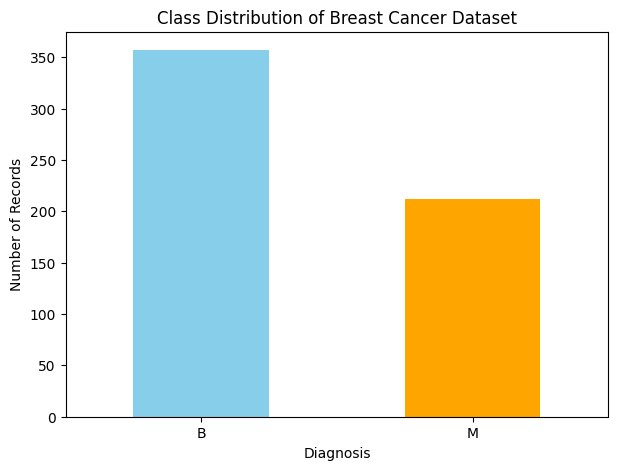

In [4]:

import matplotlib.pyplot as plt

class_counts = df['diagnosis'].value_counts()

print("Class Distribution:")
print(class_counts)

plt.figure(figsize=(7, 5))
class_counts.plot(kind='bar', color=['skyblue', 'orange'])

plt.title("Class Distribution of Breast Cancer Dataset")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.show()


In [5]:

print("Missing Values Before Handling:")
print(df.isnull().sum().sum())

df = df.drop_duplicates()

df = df.dropna()

print("\nMissing Values After Handling:")
print(df.isnull().sum().sum())

print("\nDataset Shape:")
print(df.shape)


Missing Values Before Handling:
0

Missing Values After Handling:
0

Dataset Shape:
(569, 31)


In [6]:

df['diagnosis'] = df['diagnosis'].map({
    'M': 1,
    'B': 0
})

print("Encoded Target Values:")
print(df['diagnosis'].value_counts())

print("\nFirst Five Records:")
display(df.head())


Encoded Target Values:
diagnosis
0    357
1    212
Name: count, dtype: int64

First Five Records:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


In [7]:

from sklearn.preprocessing import StandardScaler

X = df.drop('diagnosis', axis=1)
y = df['diagnosis']

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Original Features:")
display(X.head())

print("\nScaled Features:")
print(X_scaled[:5])


Original Features:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Scaled Features:
[[ 1.09706398e+00 -2.07333501e+00  1.26993369e+00  9.84374905e-01
   1.56846633e+00  3.28351467e+00  2.65287398e+00  2.53247522e+00
   2.21751501e+00  2.25574689e+00  2.48973393e+00 -5.65265059e-01
   2.83303087e+00  2.48757756e+00 -2.14001647e-01  1.31686157e+00
   7.24026158e-01  6.60819941e-01  1.14875667e+00  9.07083081e-01
   1.88668963e+00 -1.35929347e+00  2.30360062e+00  2.00123749e+00
   1.30768627e+00  2.61666502e+00  2.10952635e+00  2.29607613e+00
   2.75062224e+00  1.93701461e+00]
 [ 1.82982061e+00 -3.53632408e-01  1.68595471e+00  1.90870825e+00
  -8.26962447e-01 -4.87071673e-01 -2.38458552e-02  5.48144156e-01
   1.39236330e-03 -8.68652457e-01  4.99254601e-01 -8.76243603e-01
   2.63326966e-01  7.42401948e-01 -6.05350847e-01 -6.92926270e-01
  -4.40780058e-01  2.60162067e-01 -8.05450380e-01 -9.94437403e-02
   1.80592744e+00 -3.69203222e-01  1.53512599e+00  1.89048899e+00
  -3.75611957e-01 -4.30444219e-01 -1.46748968e-01  1.08708430e+00
  -2.43889668e-01  2.81

In [8]:

print("All Dataset Columns:")
print(df.columns.tolist())

X = df.drop('diagnosis', axis=1)
y = df['diagnosis']

print("\nFeature Columns:")
print(X.columns.tolist())

print("\nTarget Column:")
print(y.name)

print("\nFeature Shape:", X.shape)
print("Target Shape:", y.shape)


All Dataset Columns:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension', 'diagnosis']

Feature Columns:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension

In [9]:

from sklearn.model_selection import train_test_split

X = df.drop('diagnosis', axis=1)
y = df['diagnosis']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)


Training data shape: (455, 30)
Testing data shape: (114, 30)


In [10]:

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Scaled Training Shape:", X_train_scaled.shape)
print("Scaled Testing Shape:", X_test_scaled.shape)


Scaled Training Shape: (455, 30)
Scaled Testing Shape: (114, 30)


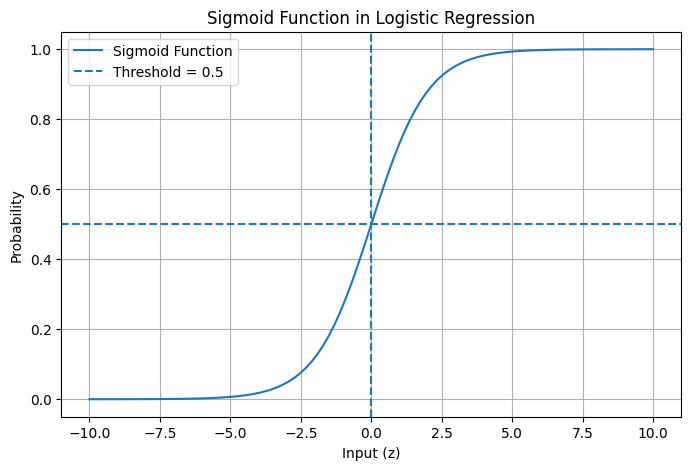

In [11]:

import numpy as np
import matplotlib.pyplot as plt

z = np.linspace(-10, 10, 100)

sigmoid = 1 / (1 + np.exp(-z))

plt.figure(figsize=(8, 5))
plt.plot(z, sigmoid, label='Sigmoid Function')

plt.axhline(y=0.5, linestyle='--', label='Threshold = 0.5')
plt.axvline(x=0, linestyle='--')

plt.title("Sigmoid Function in Logistic Regression")
plt.xlabel("Input (z)")
plt.ylabel("Probability")
plt.legend()
plt.grid()
plt.show()


In [12]:

from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model.fit(X_train_scaled, y_train)

print("Logistic Regression Model Trained Successfully!")


Logistic Regression Model Trained Successfully!


In [13]:

print("Model Settings:")
print("Penalty:", model.penalty)
print("C:", model.C)
print("Solver:", model.solver)
print("Maximum Iterations:", model.max_iter)
print("Random State:", model.random_state)

print("\nModel Intercept:")
print(model.intercept_)

print("\nModel Coefficients:")
print(model.coef_)


Model Settings:
Penalty: l2
C: 1.0
Solver: lbfgs
Maximum Iterations: 1000
Random State: 42

Model Intercept:
[-0.24300533]

Model Coefficients:
[[ 0.36115007  0.4822194   0.35315987  0.43995028  0.35062156 -0.43954615
   0.78229835  0.95281283 -0.16399087 -0.08086512  1.23332517 -0.40761126
   0.74829471  0.90902906  0.24799098 -0.9069248  -0.09234069  0.48208908
  -0.33065773 -0.59387632  0.89696783  1.43409317  0.72311148  0.90047661
   0.42020675 -0.17348751  0.9114058   0.70399881  1.06126366  0.05486988]]


In [14]:

coef_df = pd.DataFrame({
    'Feature Name': X.columns,
    'Coefficient': model.coef_[0]
})

print("Feature Coefficients:")
display(coef_df)


Feature Coefficients:


,Feature Name,Coefficient
0,mean radius,0.361150
1,mean texture,0.482219
2,mean perimeter,0.353160
3,mean area,0.439950
4,mean smoothness,0.350622
5,mean compactness,-0.439546
6,mean concavity,0.782298
7,mean concave points,0.952813
8,mean symmetry,-0.163991
9,mean fractal dimension,-0.080865


In [15]:

# Predict probabilities
y_prob = model.predict_proba(X_test_scaled)[:, 1]

# Predict class labels
y_pred = model.predict(X_test_scaled)

print("Predicted Probabilities:")
print(y_prob[:10])

print("\nPredicted Class Labels:")
print(y_pred[:10])


Predicted Probabilities:
[3.64568116e-04 9.99999989e-01 4.25679471e-02 5.76187322e-01
 5.09155489e-01 6.16001620e-04 7.61534086e-01 1.01217174e-03
 5.68725516e-04 1.07675795e-02]

Predicted Class Labels:
[0 1 0 1 1 0 1 0 0 0]


In [16]:

results = pd.DataFrame({
    'Actual Label': y_test.values,
    'Predicted Probability': y_prob,
    'Predicted Label': y_pred
})

results['Actual Label'] = results['Actual Label'].map({
    0: 'Benign',
    1: 'Malignant'
})

results['Predicted Label'] = results['Predicted Label'].map({
    0: 'Benign',
    1: 'Malignant'
})

display(results.head(10))


,Actual Label,Predicted Probability,Predicted Label
0,Benign,0.000365,Benign
1,Malignant,1.000000,Malignant
2,Benign,0.042568,Benign
3,Malignant,0.576187,Malignant
4,Benign,0.509155,Malignant
5,Benign,0.000616,Benign
6,Malignant,0.761534,Malignant
7,Benign,0.001012,Benign
8,Benign,0.000569,Benign
9,Benign,0.010768,Benign


In [17]:

thresholds = [0.3, 0.5, 0.7]

for threshold in thresholds:
    pred = (y_prob >= threshold).astype(int)

    print("Threshold:", threshold)
    print("Predicted Malignant:", (pred == 1).sum())
    print("Predicted Benign:", (pred == 0).sum())
    print("-----------------------")


Threshold: 0.3
Predicted Malignant: 42
Predicted Benign: 72
-----------------------
Threshold: 0.5
Predicted Malignant: 40
Predicted Benign: 74
-----------------------
Threshold: 0.7
Predicted Malignant: 38
Predicted Benign: 76
-----------------------


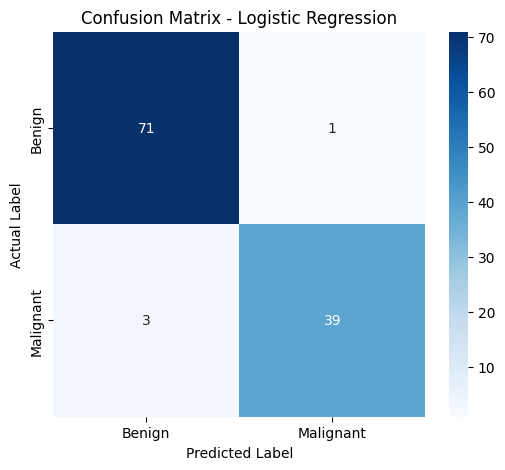

Confusion Matrix:
[[71  1]
 [ 3 39]]


In [18]:

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Benign', 'Malignant'],
    yticklabels=['Benign', 'Malignant']
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

print("Confusion Matrix:")
print(cm)


In [19]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

tn, fp, fn, tp = confusion_matrix(
    y_test, y_pred, labels=[0, 1]
).ravel()

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
specificity = tn / (tn + fp) if (tn + fp) else 0
f1 = f1_score(y_test, y_pred, zero_division=0)

print("True Negative:", tn)
print("False Positive:", fp)
print("False Negative:", fn)
print("True Positive:", tp)

print("\nAccuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("Specificity:", specificity)
print("F1 Score:", f1)


True Negative: 71
False Positive: 1
False Negative: 3
True Positive: 39

Accuracy: 0.9649122807017544
Precision: 0.975
Recall: 0.9285714285714286
Specificity: 0.9861111111111112
F1 Score: 0.9512195121951219


In [20]:

metrics_table = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'Specificity',
        'F1 Score'
    ],
    'Score': [
        accuracy,
        precision,
        recall,
        specificity,
        f1
    ]
})

metrics_table['Score'] = metrics_table['Score'].round(4)

display(metrics_table)


,Metric,Score
0,Accuracy,0.9649
1,Precision,0.9750
2,Recall,0.9286
3,Specificity,0.9861
4,F1 Score,0.9512


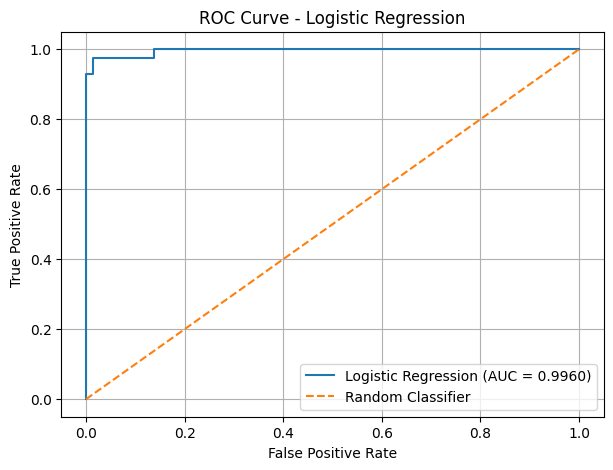

ROC-AUC Score: 0.996031746031746


In [21]:

from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

fpr, tpr, thresholds_roc = roc_curve(
    y_test,
    y_prob
)

roc_auc = roc_auc_score(
    y_test,
    y_prob
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f'Logistic Regression (AUC = {roc_auc:.4f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.title("ROC Curve - Logistic Regression")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid()
plt.show()

print("ROC-AUC Score:", roc_auc)


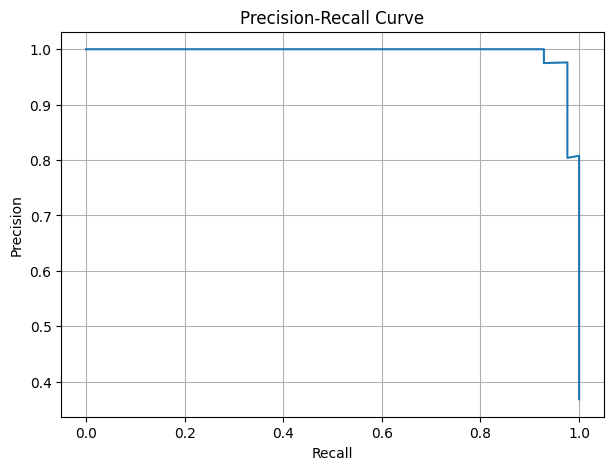

Average Precision Score: 0.994273631904294


In [22]:

from sklearn.metrics import precision_recall_curve, average_precision_score

pr_precision, pr_recall, pr_thresholds = precision_recall_curve(
    y_test,
    y_prob
)

ap_score = average_precision_score(y_test, y_prob)

plt.figure(figsize=(7, 5))

plt.plot(pr_recall, pr_precision)

plt.title("Precision-Recall Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.grid()
plt.show()

print("Average Precision Score:", ap_score)


In [23]:

from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score

thresholds = [0.3, 0.5, 0.7]

threshold_results = []

for t in thresholds:

    pred = (y_prob >= t).astype(int)

    threshold_results.append({
        'Threshold': t,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'F1 Score': f1_score(y_test, pred, zero_division=0),
        'Predicted Malignant': (pred == 1).sum()
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))


,Threshold,Accuracy,Precision,Recall,F1 Score,Predicted Malignant
0,0.3,0.9825,0.9762,0.9762,0.9762,42
1,0.5,0.9649,0.9750,0.9286,0.9512,40
2,0.7,0.9649,1.0000,0.9048,0.9500,38


In [24]:

from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

# Training predictions
y_train_pred = model.predict(X_train_scaled)

# Testing predictions
y_test_pred = model.predict(X_test_scaled)

comparison_metrics = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score'],

    'Training Score': [
        accuracy_score(y_train, y_train_pred),
        precision_score(y_train, y_train_pred),
        recall_score(y_train, y_train_pred),
        f1_score(y_train, y_train_pred)
    ],

    'Testing Score': [
        accuracy_score(y_test, y_test_pred),
        precision_score(y_test, y_test_pred),
        recall_score(y_test, y_test_pred),
        f1_score(y_test, y_test_pred)
    ]
})

display(comparison_metrics.round(4))


,Metric,Training Score,Testing Score
0,Accuracy,0.9868,0.9649
1,Precision,1.0000,0.9750
2,Recall,0.9647,0.9286
3,F1 Score,0.9820,0.9512


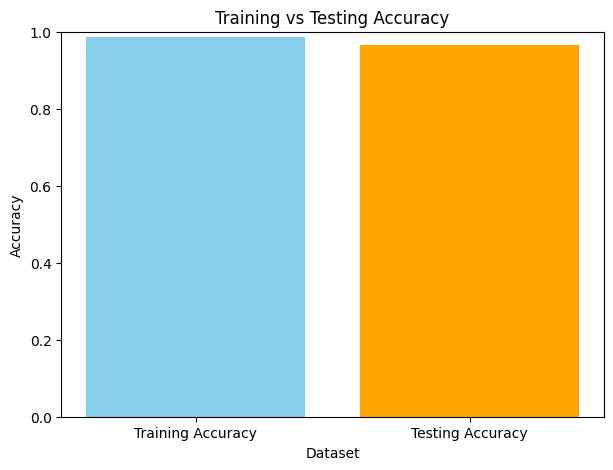

In [25]:

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

plt.figure(figsize=(7, 5))

plt.bar(
    ['Training Accuracy', 'Testing Accuracy'],
    [train_accuracy, test_accuracy],
    color=['skyblue', 'orange']
)

plt.title("Training vs Testing Accuracy")
plt.xlabel("Dataset")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.show()
